In [1]:
# ---------- CELL 0: locate the project (same in every notebook) ----------
import os, sys
from pathlib import Path

def find_root(marker="PROJECT_ROOT.marker"):
    here = Path.cwd().resolve()                      # start where this notebook runs
    for folder in [here, *here.parents]:             # go UP one level at a time
        if (folder / marker).exists():
            return folder
    if "google.colab" in sys.modules:                # Colab: look inside Google Drive
        from google.colab import drive
        drive.mount("/content/drive")
        for pattern in (marker, f"*/{marker}", f"*/*/{marker}", f"*/*/*/{marker}"):
            hits = sorted(Path("/content/drive/MyDrive").glob(pattern))
            if hits:
                return hits[0].parent
    raise FileNotFoundError("PROJECT_ROOT.marker not found - finish Day 1 first.")

ROOT = find_root()
os.chdir(ROOT / "notebooks")
RAW, CLEAN = ROOT/"data"/"raw", ROOT/"data"/"clean"
FEATURES, MODEL_OUT = ROOT/"data"/"features", ROOT/"data"/"model_outputs"
SQL_EXPORTS, BI_READY = ROOT/"data"/"sql_exports", ROOT/"data"/"bi_ready"
MODELS, REPORTS, DOCS = ROOT/"models", ROOT/"reports", ROOT/"docs"
FIGURES = REPORTS/"figures"
sys.path.append(str(ROOT/"src"))
print("Project root:", ROOT)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project root: /content/drive/MyDrive/Internmo/netflix_churn_project


In [2]:
# ---------- CELL 1: write src/features.py ----------
features_code = '''"""Builds one row per customer using ONLY data available on or before ref_date."""
import pandas as pd
import numpy as np


def build_features(ref_date, tables, last_payment_date=None):
    """
    ref_date           the snapshot date; nothing after this date is used
    tables             dict of the clean tables (customers, subscriptions, ...)
    last_payment_date  payments stop earlier than viewing in this dataset, so payment windows
                       are measured back from min(ref_date, last_payment_date)
    """
    ref = pd.Timestamp(ref_date)
    pay_ref = ref if last_payment_date is None else min(ref, pd.Timestamp(last_payment_date))

    customers, subs, plans = tables["customers"], tables["subscriptions"], tables["subscription_plans"]
    viewing, payments = tables["viewing_activity"], tables["payments"]
    tickets, feedback, churn = tables["support_tickets"], tables["customer_feedback"], tables["churn_labels"]

    # ---- 1. Who is in the table: customers registered on or before the snapshot date -------------
    out = customers.loc[customers["registration_date"] <= ref,
                        ["customer_id", "age", "gender", "customer_segment",
                         "acquisition_channel", "country", "registration_date"]].copy()
    out["tenure_days"] = (ref - out["registration_date"]).dt.days
    out = out.drop(columns="registration_date")

    # ---- 2. Subscription as it was on the snapshot date ------------------------------------------
    started = subs[subs["subscription_start_date"] <= ref].sort_values("subscription_start_date")
    plan_changes = started.groupby("customer_id").size().sub(1).rename("plan_changes_to_date")
    in_force = started[started["subscription_end_date"].isna() | (started["subscription_end_date"] > ref)]
    in_force = (in_force.groupby("customer_id").last().reset_index()
                        .merge(plans[["plan_id", "plan_name"]], on="plan_id")
                        [["customer_id", "plan_name", "auto_renew"]])

    # ---- 3. Viewing behaviour: last 30 and 90 days before the snapshot ---------------------------
    v = viewing[viewing["viewing_date"] <= ref].copy()
    v["days_ago"] = (ref - v["viewing_date"]).dt.days
    v90 = v[v["days_ago"] < 90]
    view_90 = v90.groupby("customer_id").agg(
        sessions_90d=("viewing_id", "count"),
        minutes_90d=("watch_duration_minutes", "sum"),
        avg_completion_90d=("completion_percentage", "mean"),
        distinct_titles_90d=("content_id", "nunique"))
    sessions_30d = v[v["days_ago"] < 30].groupby("customer_id").size().rename("sessions_30d")
    days_since_last_view = v.groupby("customer_id")["days_ago"].min().clip(upper=90).rename("days_since_last_view")

    # ---- 4. Payments: last 12 months before the (payment) reference date -------------------------
    p = payments[payments["payment_date"] <= pay_ref].copy()
    p["days_ago"] = (pay_ref - p["payment_date"]).dt.days
    p["is_failed"] = (p["payment_status"] == "Failed").astype(int)
    pay_12m = p[p["days_ago"] < 365].groupby("customer_id").agg(
        payments_12m=("payment_id", "count"),
        failed_payments_12m=("is_failed", "sum"))
    pay_12m["failed_rate_12m"] = pay_12m["failed_payments_12m"] / pay_12m["payments_12m"]
    failed_90d = p[p["days_ago"] < 90].groupby("customer_id")["is_failed"].sum().rename("failed_payments_90d")

    # ---- 5. Support tickets (tickets with an unknown date are dropped by the comparison) ---------
    t = tickets[tickets["ticket_date"] <= ref]
    tick = t.groupby("customer_id").agg(
        tickets_total=("ticket_id", "count"),
        avg_csat=("customer_satisfaction_score", "mean"),
        avg_resolution_hours=("resolution_time_hours", "mean"))
    tickets_365d = t[(ref - t["ticket_date"]).dt.days < 365].groupby("customer_id").size().rename("tickets_365d")

    # ---- 6. Feedback ------------------------------------------------------------------------------
    f = feedback[feedback["feedback_date"] <= ref]
    fb = f.groupby("customer_id").agg(
        feedback_count=("feedback_id", "count"),
        avg_rating=("rating", "mean"),
        negative_feedback_share=("sentiment_from_rating", lambda s: (s == "Negative").mean()))

    # ---- 7. Put everything together --------------------------------------------------------------
    out = out.merge(in_force, on="customer_id", how="left").merge(plan_changes, on="customer_id", how="left")
    for part in [view_90, sessions_30d, days_since_last_view, pay_12m, failed_90d, tick, tickets_365d, fb]:
        out = out.merge(part, left_on="customer_id", right_index=True, how="left")

    # a customer with no rows in a table has a count of 0 (not "unknown")
    zero_fill = ["sessions_90d", "minutes_90d", "distinct_titles_90d", "sessions_30d", "payments_12m",
                 "failed_payments_12m", "failed_rate_12m", "failed_payments_90d", "tickets_total",
                 "tickets_365d", "feedback_count", "plan_changes_to_date"]
    out[zero_fill] = out[zero_fill].fillna(0)
    out["days_since_last_view"] = out["days_since_last_view"].fillna(90)     # never watched = the maximum, 90
    # avg_completion_90d, avg_csat, avg_resolution_hours, avg_rating, negative_feedback_share stay blank
    # when there is nothing to average. The model pipeline on Day 10 handles blanks.

    # ---- 8. The outcome (NEVER used as a feature) and who was still a customer on the snapshot date
    out = out.merge(churn[["customer_id", "churned", "churn_date"]], on="customer_id", how="left")
    out["active_at_snapshot"] = out["churn_date"].isna() | (out["churn_date"] > ref)
    out = out.drop(columns="churn_date")
    out.insert(1, "snapshot_date", ref)
    assert out["customer_id"].is_unique
    return out
'''
(ROOT / "src" / "features.py").write_text(features_code)

import importlib, features
importlib.reload(features)
print("src/features.py written and importable")

src/features.py written and importable


In [3]:
# ---------- CELL 2: load tables, derive the snapshot dates ----------
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from features import build_features

tables = {
    "customers":          pd.read_csv(CLEAN / "customers.csv", parse_dates=["registration_date"]),
    "subscription_plans": pd.read_csv(CLEAN / "subscription_plans.csv"),
    "subscriptions":      pd.read_csv(CLEAN / "subscriptions.csv", parse_dates=["subscription_start_date", "subscription_end_date"]),
    "viewing_activity":   pd.read_csv(CLEAN / "viewing_activity.csv", parse_dates=["viewing_date"]),
    "payments":           pd.read_csv(CLEAN / "payments.csv", parse_dates=["payment_date"]),
    "support_tickets":    pd.read_csv(CLEAN / "support_tickets.csv", parse_dates=["ticket_date"]),
    "customer_feedback":  pd.read_csv(CLEAN / "customer_feedback.csv", parse_dates=["feedback_date"]),
    "churn_labels":       pd.read_csv(CLEAN / "churn_labels.csv", parse_dates=["churn_date"]),
}

AS_OF            = pd.Timestamp((CLEAN / "as_of_date.txt").read_text().strip())          # 2026-06-30
TRAIN_CUTOFF     = tables["churn_labels"]["churn_date"].min() - pd.Timedelta(days=1)      # day before the first churn
LAST_PAYMENT     = tables["payments"]["payment_date"].max()                               # 2026-05-31

FEATURES.mkdir(parents=True, exist_ok=True)
pd.DataFrame({"name": ["train_cutoff", "scoring_date", "last_payment_date"],
              "date": [TRAIN_CUTOFF.date(), AS_OF.date(), LAST_PAYMENT.date()]}).to_csv(FEATURES / "snapshot_dates.csv", index=False)
print("training cutoff:", TRAIN_CUTOFF.date(), "| scoring date:", AS_OF.date(), "| last payment:", LAST_PAYMENT.date())

training cutoff: 2025-10-02 | scoring date: 2026-06-30 | last payment: 2026-05-31


In [4]:
# ---------- CELL 3: training table (snapshot = cutoff) ----------
train = build_features(TRAIN_CUTOFF, tables, last_payment_date=LAST_PAYMENT)

# every customer in the training table must still have been a customer on the cutoff date
assert train["active_at_snapshot"].all(), "someone had already churned before the cutoff!"
assert tables["churn_labels"]["churn_date"].dropna().gt(TRAIN_CUTOFF).all()

print("training rows:", len(train), "| churned afterwards:", int(train["churned"].sum()),
      f"({100 * train['churned'].mean():.1f}%)")
train.head(3).T

training rows: 7277 | churned afterwards: 1777 (24.4%)


,0,1,2
customer_id,CUST000744,CUST005383,CUST004708
snapshot_date,2025-10-02 00:00:00,2025-10-02 00:00:00,2025-10-02 00:00:00
age,21,40,27
gender,Female,Male,Male
customer_segment,Individual,Student,Individual
acquisition_channel,Organic Search,Paid Social,Partner Bundle (Telecom)
country,United Kingdom,United Kingdom,United Kingdom
tenure_days,2313,838,2399
plan_name,Premium,Basic,Standard
auto_renew,0,1,0


In [5]:
# ---------- CELL 4: scoring table (snapshot = as-of date) ----------
scoring = build_features(AS_OF, tables, last_payment_date=LAST_PAYMENT)
print("rows:", len(scoring), "| still active on", AS_OF.date(), ":", int(scoring["active_at_snapshot"].sum()))

rows: 8000 | still active on 2026-06-30 : 6009


In [6]:
# ---------- CELL 5: checks ----------
feature_columns = [c for c in train.columns if c not in ["customer_id", "snapshot_date", "churned", "active_at_snapshot"]]
print("number of features:", len(feature_columns))

# 1) blanks per feature (some blanks are expected: nothing to average)
blanks = train[feature_columns].isna().sum()
print("\nfeatures with blanks:\n", blanks[blanks > 0])

# 2) every count must be 0 or more; every rate must be between 0 and 1
count_columns = ["sessions_90d", "minutes_90d", "tickets_total", "failed_payments_12m", "feedback_count"]
assert (train[count_columns] >= 0).all().all()
assert train["failed_rate_12m"].between(0, 1).all()
assert train["days_since_last_view"].between(0, 90).all()

# 3) leakage test: no feature may use a date after the snapshot.
#    We rebuild the training table after DELETING all later data. If any feature used future data, the result would change.
cut = {name: df.copy() for name, df in tables.items()}
cut["viewing_activity"] = cut["viewing_activity"].query("viewing_date <= @TRAIN_CUTOFF")
cut["payments"]         = cut["payments"].query("payment_date <= @TRAIN_CUTOFF")
cut["support_tickets"]  = cut["support_tickets"].query("ticket_date <= @TRAIN_CUTOFF")
cut["customer_feedback"] = cut["customer_feedback"].query("feedback_date <= @TRAIN_CUTOFF")
cut["subscriptions"]    = cut["subscriptions"].query("subscription_start_date <= @TRAIN_CUTOFF")
train_check = build_features(TRAIN_CUTOFF, cut, last_payment_date=LAST_PAYMENT)

same = train.sort_values("customer_id").reset_index(drop=True)[feature_columns].equals(
       train_check.sort_values("customer_id").reset_index(drop=True)[feature_columns])
print("\nLeakage test passed (features identical without future data):", same)
assert same

number of features: 26

features with blanks:
 avg_completion_90d         1522
avg_csat                   4782
avg_resolution_hours       4782
avg_rating                 4686
negative_feedback_share    4686
dtype: int64

Leakage test passed (features identical without future data): True


churned                  mean_stayed  mean_churned  difference_pct
failed_payments_90d            0.028         0.052            89.4
failed_payments_12m            0.129         0.209            62.0
failed_rate_12m                0.019         0.029            50.2
negative_feedback_share        0.269         0.340            26.7
tickets_365d                   0.199         0.251            26.1
payments_12m                   2.126         2.642            24.2
avg_csat                       3.325         2.990           -10.1
plan_changes_to_date           0.082         0.090             9.8
tenure_days                 1252.373      1146.416            -8.5
minutes_90d                   91.641        99.131             8.2
avg_rating                     3.224         2.983            -7.5
sessions_90d                   1.896         2.028             7.0
distinct_titles_90d            1.891         2.024             7.0
avg_resolution_hours          17.554        18.520            

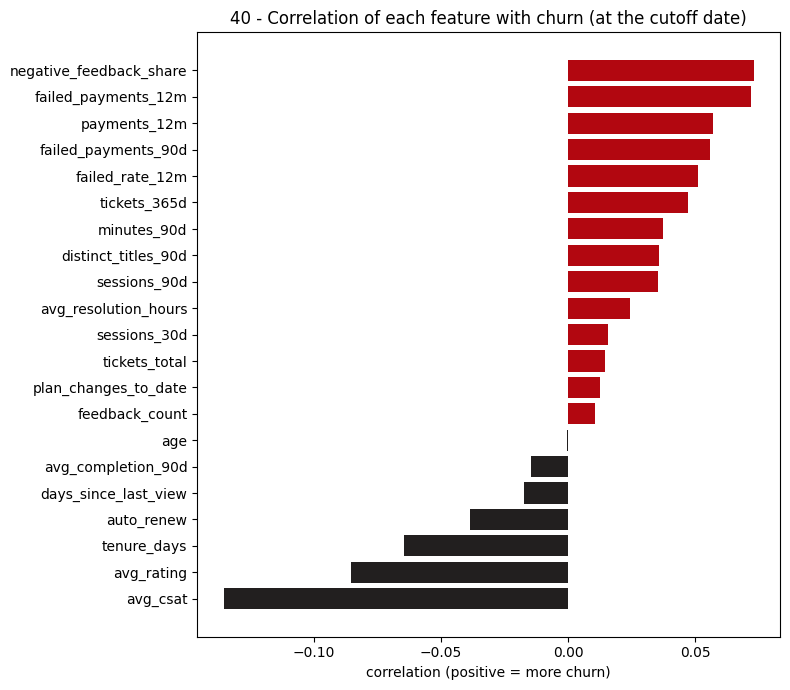

In [7]:
# ---------- CELL 6: feature vs churn ----------
numeric = train[feature_columns].select_dtypes("number").columns

comparison = (train.groupby("churned")[list(numeric)].mean().T
                   .rename(columns={0: "mean_stayed", 1: "mean_churned"}))
comparison["difference_pct"] = (100 * (comparison["mean_churned"] - comparison["mean_stayed"]) / comparison["mean_stayed"].replace(0, np.nan)).round(1)
display_table = comparison.round(3).sort_values("difference_pct", key=lambda s: s.abs(), ascending=False)
print(display_table)

corr = train[list(numeric) + ["churned"]].corr()["churned"].drop("churned").sort_values()
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(corr.index, corr.values, color=["#b20710" if v > 0 else "#221f1f" for v in corr.values])
ax.set_title("40 - Correlation of each feature with churn (at the cutoff date)")
ax.set_xlabel("correlation (positive = more churn)")
plt.tight_layout(); plt.savefig(FIGURES / "40_feature_correlation_with_churn.png", bbox_inches="tight"); plt.show()

In [8]:
# ---------- CELL 7: save the feature tables ----------
train.to_csv(FEATURES / "customer_features_train.csv", index=False)
scoring.to_csv(FEATURES / "customer_features_scoring.csv", index=False)
print("saved:", (FEATURES / "customer_features_train.csv").relative_to(ROOT), len(train), "rows")
print("saved:", (FEATURES / "customer_features_scoring.csv").relative_to(ROOT), len(scoring), "rows")

saved: data/features/customer_features_train.csv 7277 rows
saved: data/features/customer_features_scoring.csv 8000 rows


In [9]:
# ---------- CELL 8: feature dictionary ----------
feature_dictionary = pd.DataFrame([
    ("age",                     "customers",         "-",                   "Customer age (cleaned on Day 2)"),
    ("gender",                  "customers",         "-",                   "Gender as recorded"),
    ("customer_segment",        "customers",         "-",                   "Student, Corporate Bundle, ..."),
    ("acquisition_channel",     "customers",         "-",                   "How the customer was acquired"),
    ("country",                 "customers",         "-",                   "Country (cleaned on Days 2-3)"),
    ("tenure_days",             "customers",         "to snapshot",         "Days from registration to the snapshot date"),
    ("plan_name",               "subscriptions",     "at snapshot",         "Plan in force on the snapshot date"),
    ("auto_renew",              "subscriptions",     "as extracted",        "1 = auto-renew on (may carry slight future information)"),
    ("plan_changes_to_date",    "subscriptions",     "to snapshot",         "Number of plan changes so far"),
    ("sessions_30d",            "viewing_activity",  "last 30 days",        "Viewing sessions"),
    ("sessions_90d",            "viewing_activity",  "last 90 days",        "Viewing sessions"),
    ("minutes_90d",             "viewing_activity",  "last 90 days",        "Minutes watched"),
    ("avg_completion_90d",      "viewing_activity",  "last 90 days",        "Average completion %, blank if no sessions"),
    ("distinct_titles_90d",     "viewing_activity",  "last 90 days",        "Different titles watched"),
    ("days_since_last_view",    "viewing_activity",  "capped at 90",        "Days since the last session (90 = none or older)"),
    ("payments_12m",            "payments",          "last 12 months",      "Payments attempted"),
    ("failed_payments_12m",     "payments",          "last 12 months",      "Failed payments"),
    ("failed_rate_12m",         "payments",          "last 12 months",      "Failed / attempted"),
    ("failed_payments_90d",     "payments",          "last 90 days",        "Failed payments"),
    ("tickets_total",           "support_tickets",   "to snapshot",         "All tickets with a known date"),
    ("tickets_365d",            "support_tickets",   "last 12 months",      "Tickets"),
    ("avg_csat",                "support_tickets",   "to snapshot",         "Average satisfaction score, blank if none"),
    ("avg_resolution_hours",    "support_tickets",   "to snapshot",         "Average hours to resolve, blank if none"),
    ("feedback_count",          "customer_feedback", "to snapshot",         "Feedback rows"),
    ("avg_rating",              "customer_feedback", "to snapshot",         "Average star rating, blank if none"),
    ("negative_feedback_share", "customer_feedback", "to snapshot",         "Share of feedback with rating 1-2, blank if none"),
    ("churned",                 "churn_labels",      "after snapshot",      "TARGET: 1 = churned after the snapshot date. Never a feature"),
], columns=["feature", "source_table", "time_window", "description"])

assert set(feature_dictionary["feature"]) - {"churned"} == set(feature_columns), "dictionary and table do not match"
feature_dictionary.to_csv(DOCS / "feature_dictionary.csv", index=False)
print("feature dictionary saved:", len(feature_dictionary), "rows")

feature dictionary saved: 27 rows


In [10]:
# ---------- CELL 9: project log ----------
with open(DOCS / "project_log.md", "a") as f:
    f.write(f"""## Day 9 - Feature engineering
- src/features.py builds features for any snapshot date using only data on or before it.
- Training snapshot = {TRAIN_CUTOFF.date()} (day before the first churn). Scoring snapshot = {AS_OF.date()}.
- data/features/customer_features_train.csv ({len(train)} rows, {len(feature_columns)} features) and customer_features_scoring.csv.
- Leakage test passed. Banned columns: subscription_status, cancellation_*, churn_date, churn_reason.
- Caveat: auto_renew is as-extracted; Day 10 checks its influence.

""")